# Clasificación de paisajes y escenas con aprendizaje profundo
**Iris Giselle Balderas Arreola**  
**A01752895**

## Introducción
Se planteó clasificar fotografías en seis categorías: **edificios, bosque, glaciar, montaña, mar y calle**. Una aplicación posible es organizar automáticamente fotografías de viajes o apoyar la búsqueda de imágenes por su contenido.

Se eligió *Intel Image Classification*, disponible en Kaggle, porque contiene fotografías de escenas reales con variación de composición, color e iluminación. No es un dataset de juguete como MNIST. No se encontró este dataset entre los ejemplos de las 13 presentaciones proporcionadas; esta revisión no permite comprobar prácticas que no hayan sido compartidas.

Se implementó una CNN inicial y después se cambió el extractor visual por una red preentrenada. El propósito fue aplicar convoluciones, pooling, validación, regularización, aumento de datos y transferencia de aprendizaje. Se usaron TensorFlow y Keras en ambos experimentos.

In [1]:
# Se configuraron el entorno y las semillas para hacer el experimento reproducible.
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"
from pathlib import Path
import json, time, hashlib, shutil, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from IPython.display import display, Markdown
from predecir import cargar_imagen, predecir_imagen

BASE = Path.cwd()
SEMILLA = 42
LADO = 128
BATCH = 32
CLASES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
NOMBRES = ["Edificios", "Bosque", "Glaciar", "Montaña", "Mar", "Calle"]
keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()
for carpeta in ["datos", "modelos", "resultados", "ejemplos"]:
    (BASE / carpeta).mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Tamaño de imagen:", (LADO, LADO, 3), "| semilla:", SEMILLA)

TensorFlow: 2.20.0
Tamaño de imagen: (128, 128, 3) | semilla: 42


## Datos
**Fuente:** https://www.kaggle.com/datasets/puneet6060/intel-image-classification  
**Versión utilizada:** 2. Publicado por Puneet Bansal, a partir del desafío de clasificación de Intel en Analytics Vidhya.

El dataset contiene carpetas de entrenamiento, prueba y predicción sin etiquetas. La ficha indica fotografías de alrededor de 150 × 150 píxeles de seis clases. Se reportan a continuación los archivos efectivamente leídos. Los derechos de los datos corresponden a sus autores originales, según la ficha de Kaggle; no se atribuye una licencia abierta distinta.

Para reducir el tiempo se decidió utilizar **300 imágenes por clase para entrenamiento, 80 para validación y 100 para prueba**. Se conservaron las seis clases. El muestreo se fijó con semilla 42, antes de entrenar y sin seleccionar imágenes por el resultado del modelo. Las métricas representan esta muestra balanceada, no todo el dataset.

Antes de muestrear se revisaron todas las imágenes etiquetadas, se descartaron archivos ilegibles y se calcularon hashes RGB. Se retiraron grupos con etiquetas contradictorias y copias exactas, dando prioridad al conjunto oficial de prueba cuando existían copias entre carpetas. Así, ninguna imagen de prueba podría aparecer en entrenamiento por tener otro nombre. No se garantiza detectar todas las fotos casi idénticas.

In [2]:
# Se descargó la versión 2 del dataset si no estaba disponible.
raiz_datos = BASE / "datos/imagenes"
if not (raiz_datos / "seg_train").exists():
    enlace = "https://www.kaggle.com/api/v1/datasets/download/puneet6060/intel-image-classification?datasetVersionNumber=2"
    archivo_zip = BASE / "datos/descarga.zip"
    peticion = urllib.request.Request(enlace, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(peticion, timeout=180) as respuesta, archivo_zip.open("wb") as destino:
        shutil.copyfileobj(respuesta, destino)
    with zipfile.ZipFile(archivo_zip) as archivo:
        archivo.extractall(raiz_datos)
    archivo_zip.unlink()
print("Dataset disponible:", raiz_datos.name)

# Se revisaron todas las imágenes etiquetadas antes de seleccionar la muestra.
filas, errores_lectura = [], []
for carpeta in ["seg_test", "seg_train"]:
    for ruta in sorted((raiz_datos / carpeta).rglob("*.jpg")):
        try:
            with Image.open(ruta) as imagen:
                rgb = ImageOps.exif_transpose(imagen).convert("RGB")
                huella = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
                ancho, alto = rgb.size
            filas.append({"archivo": ruta.relative_to(raiz_datos).as_posix(),
                          "clase": ruta.parent.name, "origen": carpeta,
                          "hash_rgb": huella, "ancho": ancho, "alto": alto})
        except (OSError, ValueError) as error:
            errores_lectura.append({"archivo": str(ruta), "error": str(error)})
inventario = pd.DataFrame(filas)
assert set(inventario.clase) == set(CLASES)
contradicciones = inventario.groupby("hash_rgb").clase.nunique()
limpios = inventario[~inventario.hash_rgb.isin(contradicciones[contradicciones.gt(1)].index)].drop_duplicates("hash_rgb").copy()
limpios["etiqueta"] = limpios.clase.map({clase: i for i, clase in enumerate(CLASES)})
inventario.to_csv(BASE / "resultados/auditoria.csv", index=False)
print("Archivos etiquetados legibles:", len(inventario))
print("Archivos ilegibles:", len(errores_lectura))
print("Grupos con etiquetas contradictorias:", int(contradicciones.gt(1).sum()))
print("Imágenes únicas:", len(limpios), "| filas retiradas:", len(inventario)-len(limpios))
display(pd.crosstab(limpios.clase, limpios.origen))

Dataset disponible: imagenes
Archivos etiquetados legibles: 17034
Archivos ilegibles: 0
Grupos con etiquetas contradictorias: 13
Imágenes únicas: 17003 | filas retiradas: 31


origen,seg_test,seg_train
clase,,
buildings,436,2187
forest,474,2269
glacier,552,2398
mountain,525,2504
sea,510,2272
street,500,2376


In [3]:
# Se construyeron particiones balanceadas usando solamente las carpetas correspondientes.
train_partes, val_partes, test_partes = [], [], []
for clase in CLASES:
    disponibles = limpios[limpios.clase.eq(clase) & limpios.origen.eq("seg_train")]
    seleccion = disponibles.sample(380, random_state=SEMILLA)
    train_clase, val_clase = train_test_split(seleccion, test_size=80, random_state=SEMILLA)
    train_partes.append(train_clase)
    val_partes.append(val_clase)
    test_partes.append(limpios[limpios.clase.eq(clase) & limpios.origen.eq("seg_test")].sample(100, random_state=SEMILLA))
entreno = pd.concat(train_partes).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
validacion = pd.concat(val_partes).reset_index(drop=True)
prueba = pd.concat(test_partes).reset_index(drop=True)
assert set(entreno.hash_rgb).isdisjoint(validacion.hash_rgb)
assert set(entreno.hash_rgb).isdisjoint(prueba.hash_rgb)
assert set(validacion.hash_rgb).isdisjoint(prueba.hash_rgb)
particiones = pd.concat([tabla.assign(conjunto=nombre) for nombre, tabla in
                        [("entrenamiento", entreno), ("validacion", validacion), ("prueba", prueba)]])
particiones.to_csv(BASE / "resultados/particiones.csv", index=False)
display(pd.crosstab(particiones.conjunto, particiones.clase))
print("Se verificó que no existieran hashes compartidos entre las particiones.")

Se verificó que no existieran hashes compartidos entre las particiones.


clase,buildings,forest,glacier,mountain,sea,street
conjunto,,,,,,
entrenamiento,300,300,300,300,300,300
prueba,100,100,100,100,100,100
validacion,80,80,80,80,80,80


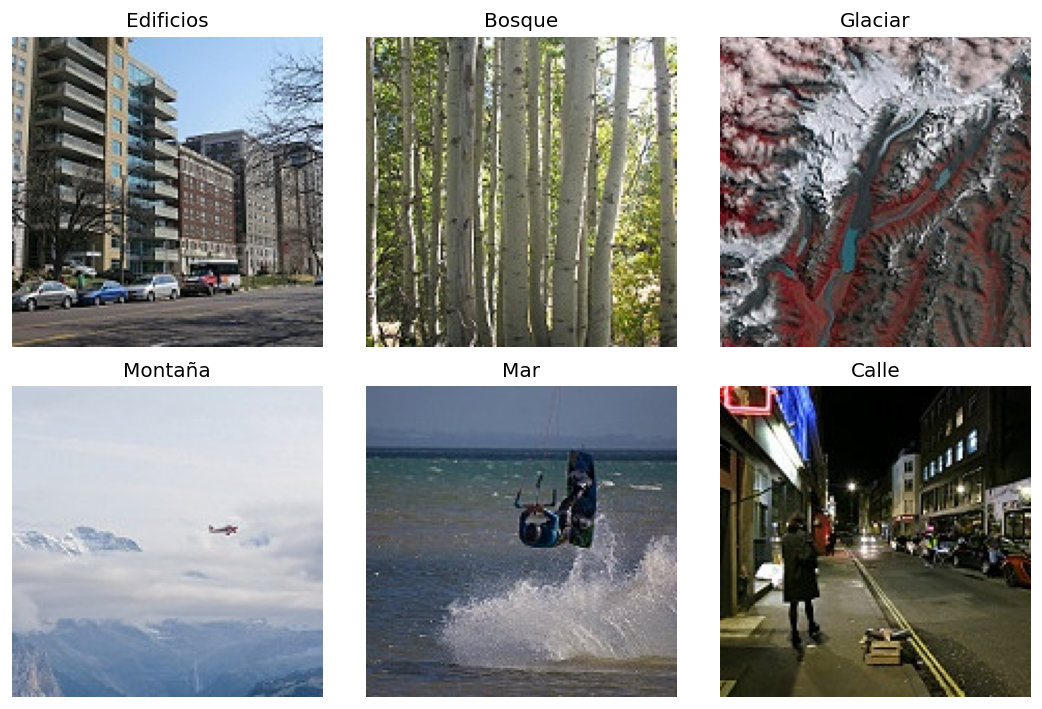

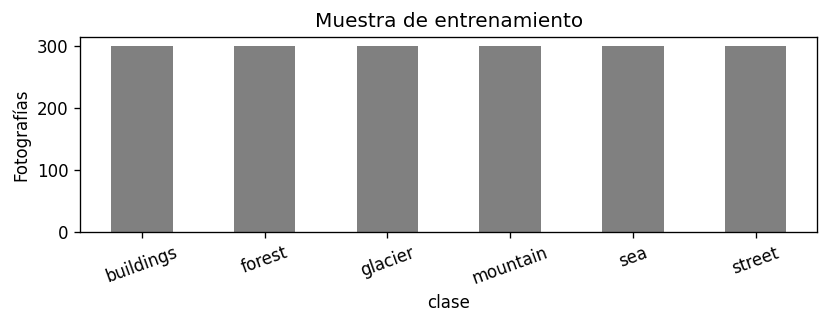

In [4]:
# Se visualizaron ejemplos de entrenamiento y su distribución.
fig, ejes = plt.subplots(2, 3, figsize=(9, 6))
for indice, ax in enumerate(ejes.ravel()):
    fila = entreno[entreno.clase.eq(CLASES[indice])].iloc[0]
    with Image.open(raiz_datos / fila.archivo) as imagen:
        ax.imshow(imagen)
    ax.set_title(NOMBRES[indice])
    ax.axis("off")
plt.tight_layout()
plt.savefig(BASE / "resultados/muestras.png", dpi=140)
plt.show()
fig, ax = plt.subplots(figsize=(7, 2.8))
entreno.clase.value_counts().reindex(CLASES).plot.bar(ax=ax, color="gray", rot=20)
ax.set(title="Muestra de entrenamiento", ylabel="Fotografías")
plt.tight_layout()
plt.savefig(BASE / "resultados/distribucion.png", dpi=140)
plt.show()

### Preprocesamiento
Se corrigió la orientación de las imágenes, se convirtieron a RGB y se redimensionaron a **128 × 128** mediante interpolación bilineal. La función de la aplicación utiliza exactamente el mismo procesamiento. Los modelos reciben píxeles de 0 a 255 y contienen el reescalado requerido.

Las etiquetas son enteros de 0 a 5. Se mantuvieron los datos de validación sin aumento de imágenes; prueba se cargará después de elegir la configuración. El redimensionamiento puede perder detalle y alterar ligeramente proporciones, lo que constituye una limitación.

In [5]:
# Se cargaron entrenamiento y validación a la resolución elegida.
def cargar_tabla(tabla):
    x = np.stack([cargar_imagen(raiz_datos / archivo, LADO) for archivo in tabla.archivo])
    return x, tabla.etiqueta.to_numpy(dtype="int32")

def crear_dataset(x, y=None, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices(x if y is None else (x, y))
    if mezclar:
        ds = ds.shuffle(len(x), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 1
    return ds.batch(BATCH).with_options(opciones).prefetch(1)

x_ent, y_ent = cargar_tabla(entreno)
x_val, y_val = cargar_tabla(validacion)
ds_ent = crear_dataset(x_ent, y_ent, True)
ds_val = crear_dataset(x_val, y_val)
print("Entrenamiento:", x_ent.shape, "| validación:", x_val.shape)
print("Rango de entrada:", x_ent.min(), "a", x_ent.max())

Entrenamiento: (1800, 128, 128, 3) | validación: (480, 128, 128, 3)
Rango de entrada: 0.0 a 255.0


## Desarrollo del modelo
Se construyó una CNN inicial con tres bloques **Conv2D → MaxPooling**, con 16, 32 y 64 filtros. Se utilizó ReLU, GlobalAveragePooling, una capa densa de 64 unidades y una salida softmax de seis unidades.

Las convoluciones conservan relaciones espaciales y aprenden patrones locales, mientras pooling reduce el tamaño de los mapas. GlobalAveragePooling permite resumir cada mapa sin crear una capa densa demasiado grande.

Se usó Adam con tasa 0.001, entropía cruzada categórica dispersa y batch de 32. Se permitió un máximo de 12 épocas y se conservaron los pesos de menor pérdida de validación. Se evaluó accuracy y F1 macro; F1 macro pondera por igual a las seis clases.

In [6]:
# Se implementó y entrenó la CNN inicial.
keras.utils.set_random_seed(SEMILLA)
inicial = keras.Sequential([
    keras.Input((LADO, LADO, 3)),
    layers.Rescaling(1/255),
    layers.Conv2D(16, 3, strides=2, padding="same", activation="relu", kernel_initializer="he_uniform"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu", kernel_initializer="he_uniform"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu", kernel_initializer="he_uniform"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
], name="cnn_escenas")
inicial.compile(optimizer=keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
inicial.summary()
inicio = time.perf_counter()
h_inicial = inicial.fit(ds_ent, validation_data=ds_val, epochs=12, verbose=2, shuffle=False,
    callbacks=[keras.callbacks.ModelCheckpoint(str(BASE / "modelos/inicial.keras"), monitor="val_loss", save_best_only=True),
               keras.callbacks.EarlyStopping(monitor="val_loss", patience=4)])
seg_inicial = time.perf_counter()-inicio
inicial = keras.models.load_model(BASE / "modelos/inicial.keras")
def evaluar(y, valores):
    pred = valores.argmax(axis=1)
    return {"accuracy": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro", zero_division=0)}
metricas_inicial = evaluar(y_val, inicial.predict(ds_val, verbose=0))
print("Validación inicial:", metricas_inicial)
print("Segundos de entrenamiento:", round(seg_inicial, 2))

Model: "cnn_escenas"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────

## Ajuste del modelo
Se sustituyó el extractor visual por **MobileNetV3Small**, preentrenada en ImageNet, con `alpha=0.75`, sin su clasificador original y con pooling promedio. La base se mantuvo congelada. Incluye convoluciones especializadas, por lo que el modelo completo no está formado solamente por capas densas.

Se entrenó una cabeza de seis clases con dropout 0.3 y regularización L2 de 0.0001. Se mantuvo Adam con tasa 0.001 y se permitió un máximo de 35 épocas con early stopping, paciencia de 5 y recuperación de los pesos de menor pérdida de validación.

Se aplicó un aumento sencillo **solo a entrenamiento**: una copia reflejada horizontalmente por cada imagen. Para estas escenas, intercambiar izquierda y derecha suele conservar la categoría; no se utilizaron inversiones verticales ni rotaciones fuertes que alteraran la orientación del paisaje.

Como la base está congelada, se calcularon una sola vez las características de las imágenes originales y reflejadas. Se entrenó después la cabeza sobre esas características para reducir el costo. Esto no es fine tuning de la base. Se compararon dos configuraciones completas; no se puede aislar el efecto de cada cambio porque se modificaron varios elementos juntos.

**Resolución del preentrenamiento.** Los pesos disponibles de MobileNetV3Small fueron preentrenados con imágenes de 224 × 224. En este proyecto se utiliza entrada de 128 × 128 para reducir el costo; la base convolucional sin su clasificador admite ese tamaño. El aviso que muestra Keras informa que se cargaron los pesos de 224 × 224, no que el entrenamiento haya fallado. La evaluación reportada corresponde a la entrada de 128 × 128.

In [7]:
# Se extrajeron características con MobileNetV3Small congelada.
keras.utils.set_random_seed(SEMILLA)
inicio = time.perf_counter()
base_visual = keras.applications.MobileNetV3Small(input_shape=(LADO, LADO, 3), alpha=0.75,
    weights="imagenet", include_top=False, pooling="avg", include_preprocessing=True)
base_visual.trainable = False
# Se mantuvo el reescalado incorporado en MobileNetV3; no se normalizó dos veces.
f_ent = base_visual.predict(crear_dataset(x_ent), verbose=0)
f_reflejo = base_visual.predict(crear_dataset(x_ent[:, :, ::-1, :].copy()), verbose=0)
f_val = base_visual.predict(crear_dataset(x_val), verbose=0)
f_aumentadas = np.concatenate([f_ent, f_reflejo])
y_aumentadas = np.concatenate([y_ent, y_ent])
seg_extraccion = time.perf_counter()-inicio
print("Características originales:", f_ent.shape, "| aumentadas:", f_aumentadas.shape)
print("Parámetros de la base:", base_visual.count_params(), "| entrenables de la base: 0")
print("Segundos de preparación y extracción:", round(seg_extraccion, 2))

Características originales: (1800, 432) | aumentadas: (3600, 432)
Parámetros de la base: 583160 | entrenables de la base: 0
Segundos de preparación y extracción: 8.17


/home/agent/.local/lib/python3.12/site-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


In [8]:
# Se entrenó la cabeza del modelo ajustado.
cabeza = keras.Sequential([
    keras.Input((f_ent.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax", kernel_regularizer=keras.regularizers.l2(0.0001))
], name="clasificador_escenas")
cabeza.compile(optimizer=keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cabeza.summary()
inicio = time.perf_counter()
h_ajustado = cabeza.fit(crear_dataset(f_aumentadas, y_aumentadas, True),
    validation_data=crear_dataset(f_val, y_val), epochs=35, verbose=2, shuffle=False,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
seg_cabeza = time.perf_counter()-inicio
entrada = keras.Input((LADO, LADO, 3))
ajustado = keras.Model(entrada, cabeza(base_visual(entrada, training=False)), name="escenas_transferencia")
ajustado.save(BASE / "modelos/ajustado.keras")
metricas_ajustado = evaluar(y_val, ajustado.predict(ds_val, verbose=0))
comparacion = pd.DataFrame([
    {"modelo": "CNN inicial", **metricas_inicial, "segundos": seg_inicial},
    {"modelo": "Transferencia y regularización", **metricas_ajustado, "segundos": seg_extraccion+seg_cabeza}])
comparacion.to_csv(BASE / "resultados/comparacion_validacion.csv", index=False)
display(comparacion.round(4))
# Se fijó F1 macro de validación como criterio de selección, conservando el inicial en empate.
elegido = "ajustado" if metricas_ajustado["f1_macro"] > metricas_inicial["f1_macro"] else "inicial"
modelo_final = ajustado if elegido == "ajustado" else inicial
print("Modelo elegido:", elegido)

Model: "clasificador_escenas"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout (Dropout)               │ (None, 432)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         2,598 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 2,598 (10.15 KB)
 Trainable params: 2,598 (10.15 KB)
 Non-trainable params: 0 (0.00 B)
Epoch 1/35
113/113 - 1s - 8ms/step - accuracy: 0.6297 - loss: 0.9900 - val_accuracy: 0.8333 - val_loss: 0.4824
Epoch 2/35
113/113 - 0s - 2ms/step - accuracy: 0.8225 - loss: 0.4996 - val_accuracy: 0.8479 - val_loss: 0.3906
Epoch 3/35
113/113 - 0s - 1ms/step - accuracy: 0.8519 - loss: 0.4101 - val_accuracy: 0.8667 - val_loss: 0.3

,modelo,accuracy,f1_macro,segundos
0,CNN inicial,0.6792,0.6820,15.2720
1,Transferencia y regularización,0.8812,0.8812,11.5682


Cambio de F1 macro de validación: 0.1992
Mejor época inicial por val_loss: 12
Mejor época ajustada por val_loss: 10


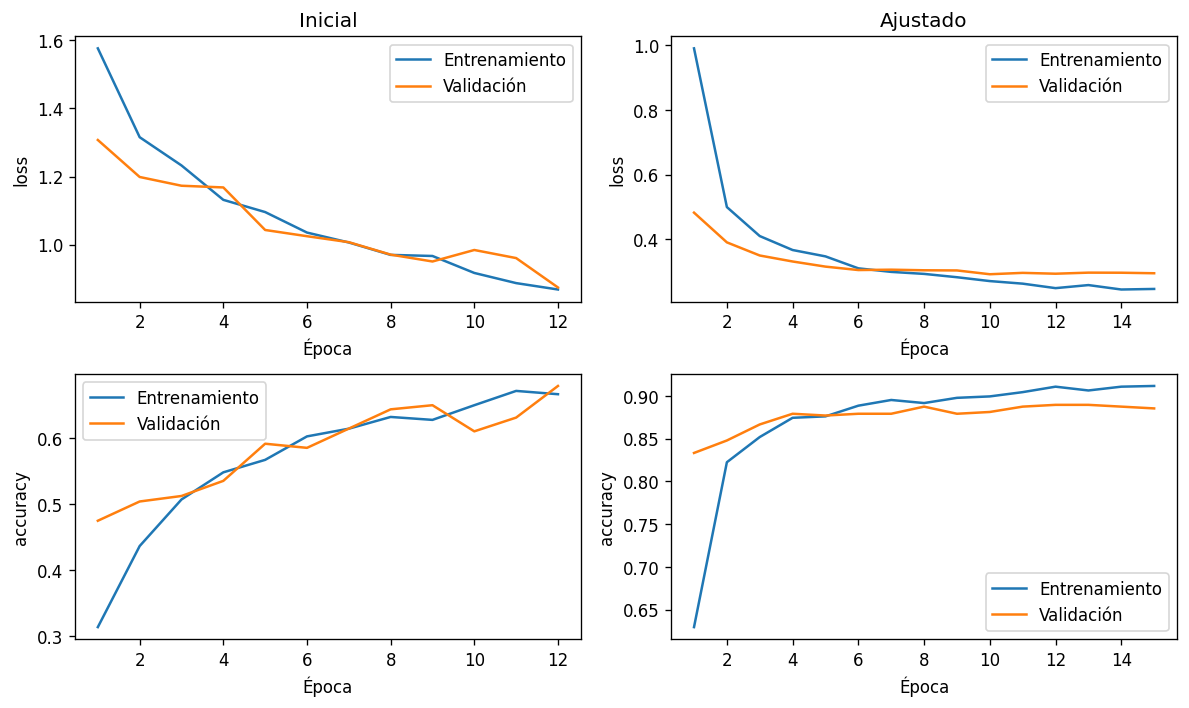

In [9]:
# Se compararon las curvas para revisar aprendizaje y señales de sobreajuste.
fig, ejes = plt.subplots(2, 2, figsize=(10, 6))
for columna, (titulo, hist) in enumerate([("Inicial", h_inicial.history), ("Ajustado", h_ajustado.history)]):
    epocas = np.arange(1, len(hist["loss"])+1)
    for fila, metrica in enumerate(["loss", "accuracy"]):
        ejes[fila, columna].plot(epocas, hist[metrica], label="Entrenamiento")
        ejes[fila, columna].plot(epocas, hist["val_"+metrica], label="Validación")
        ejes[fila, columna].set(title=titulo if fila == 0 else "", xlabel="Época", ylabel=metrica)
        ejes[fila, columna].legend()
plt.tight_layout()
plt.savefig(BASE / "resultados/curvas_entrenamiento.png", dpi=140)
plt.show()
for nombre, historial in [("inicial", h_inicial.history), ("ajustado", h_ajustado.history)]:
    pd.DataFrame(historial).to_csv(BASE / f"resultados/historia_{nombre}.csv", index=False)
cambio_f1 = metricas_ajustado["f1_macro"]-metricas_inicial["f1_macro"]
print("Cambio de F1 macro de validación:", round(cambio_f1, 4))
print("Mejor época inicial por val_loss:", int(np.argmin(h_inicial.history["val_loss"]))+1)
print("Mejor época ajustada por val_loss:", int(np.argmin(h_ajustado.history["val_loss"]))+1)

La revisión del sobreajuste considera si la pérdida de entrenamiento disminuye mientras la de validación empeora, así como la separación de las curvas. Dropout se activa solamente al entrenar y la pérdida del modelo ajustado incluye L2; por tanto, la pérdida de validación puede ser menor que la de entrenamiento sin ser un error. Early stopping y regularización ayudan a controlarlo, pero no demuestran su ausencia.

## Resultados
Se utilizó el conjunto de prueba únicamente después de seleccionar el modelo. Se calculó accuracy, F1 macro y un reporte por clase. La matriz de confusión permite identificar categorías que se confunden, como glaciar y montaña o edificios y calle.

**Diagnóstico de esta ejecución.** La CNN inicial terminó con pérdidas de entrenamiento y validación cercanas (aproximadamente 0.869 y 0.875) y seguía mejorando al llegar a 12 épocas. Esto apunta a margen de mejora de representación u optimización, más que a una brecha grande por sobreajuste. En el modelo ajustado, la pérdida de validación alcanzó su mínimo de aproximadamente 0.292 en la época 10 y después se estabilizó con pequeñas oscilaciones, mientras la pérdida de entrenamiento continuó bajando. Early stopping se activó en la época 15 y recuperó los pesos de la época 10. Se observa una brecha moderada al final, por lo que no se afirma ausencia total de sobreajuste.

Prueba: {'accuracy': 0.87, 'f1_macro': 0.8700316262726552}
              precision    recall  f1-score   support

   Edificios     0.8725    0.8900    0.8812       100
      Bosque     1.0000    0.9700    0.9848       100
     Glaciar     0.7670    0.7900    0.7783       100
     Montaña     0.8105    0.7700    0.7897       100
         Mar     0.8774    0.9300    0.9029       100
       Calle     0.8969    0.8700    0.8832       100

    accuracy                         0.8700       600
   macro avg     0.8707    0.8700    0.8700       600
weighted avg     0.8707    0.8700    0.8700       600

Accuracy de una predicción constante en esta muestra balanceada: 0.1667


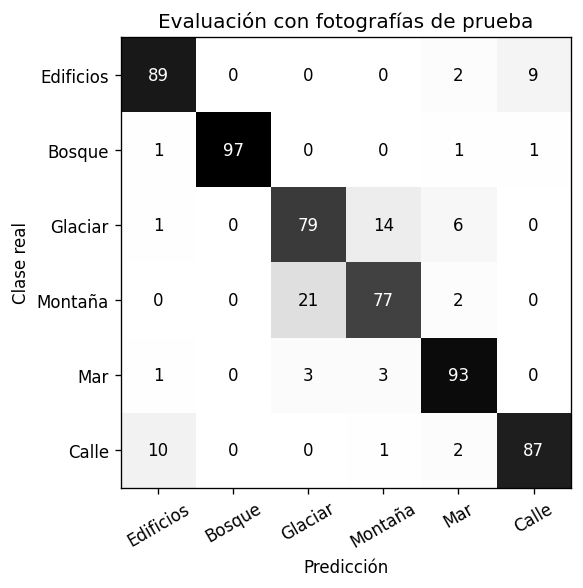

,archivo,clase,hash_rgb,prediccion,puntuacion
12,seg_test/seg_test/buildings/22240.jpg,buildings,312b4a814f6cc80d85a5633d1c42016a85461296bed851...,street,0.777087
13,seg_test/seg_test/buildings/23854.jpg,buildings,bd5d13de347a6f8ae36c3878fee05f56b36b0d74581a93...,street,0.727150
15,seg_test/seg_test/buildings/20752.jpg,buildings,70d6d2054b4e2899b34a5e2c65c5755f661178c2f89420...,street,0.901403
31,seg_test/seg_test/buildings/23512.jpg,buildings,028ae35283d79db813bac7aa6d5ee6cf2700d678a041ba...,street,0.943070
34,seg_test/seg_test/buildings/23635.jpg,buildings,03a402180829eb1b6f81228016e357e05596b9e3b62a32...,sea,0.966855
63,seg_test/seg_test/buildings/22741.jpg,buildings,e3a85c05e7d31ff259eccb7a63630b02fe99b31167a641...,street,0.977132


In [10]:
# Se evaluó una sola vez la configuración elegida en la muestra de prueba.
x_test, y_test = cargar_tabla(prueba)
prob_test = modelo_final.predict(crear_dataset(x_test), verbose=0)
pred_test = prob_test.argmax(axis=1)
metricas_test = evaluar(y_test, prob_test)
print("Prueba:", metricas_test)
print(classification_report(y_test, pred_test, labels=range(6), target_names=NOMBRES, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, labels=range(6), display_labels=NOMBRES,
                                       cmap="Greys", colorbar=False, ax=ax, xticks_rotation=30)
ax.set(title="Evaluación con fotografías de prueba", xlabel="Predicción", ylabel="Clase real")
plt.tight_layout()
plt.savefig(BASE / "resultados/matriz_confusion.png", dpi=140)
plt.show()
revision = prueba[["archivo", "clase", "hash_rgb"]].copy()
revision["prediccion"] = [CLASES[i] for i in pred_test]
revision["puntuacion"] = prob_test.max(axis=1)
revision.to_csv(BASE / "resultados/predicciones_prueba.csv", index=False)
display(revision[revision.clase.ne(revision.prediccion)].head(6))
print("Accuracy de una predicción constante en esta muestra balanceada:", round(1/6, 4))

**Análisis de errores.** Se observaron 35 confusiones entre glaciar y montaña (14 glaciares predichos como montaña y 21 montañas como glaciar), y 19 entre edificios y calle. Es posible que los elementos visuales compartidos, como relieve o construcciones, expliquen parte de esos errores; la matriz por sí sola no demuestra esa causa. Bosque tuvo el mayor recall (97 de 100), mientras montaña tuvo el menor (77 de 100). La demostración también conserva un error: una fotografía etiquetada como montaña se predijo como mar, en lugar de seleccionar únicamente ejemplos acertados.

## Conclusiones
Se interpretan a continuación los resultados medidos. Se distingue lo observado en esta ejecución de las explicaciones que requerirían experimentos adicionales.

In [11]:

mejora = ("mejoró" if cambio_f1 > 0 else "no mejoró")
explicacion = ("La mejora es compatible con la utilidad de características preentrenadas, junto con reflejos horizontales y regularización. "
    "La base congelada permite aprovechar una representación visual sin ajustar todos sus parámetros con esta muestra pequeña. "
    "No se aisló la contribución individual de cada técnica." if cambio_f1 > 0 else
    "La hipótesis de mejora no se confirmó con F1 de validación; se conservó la configuración con mejor resultado.")
display(Markdown(f"""Se obtuvo **accuracy de {metricas_test['accuracy']:.2%}** y **F1 macro de {metricas_test['f1_macro']:.4f}** en las 600 imágenes de prueba. El ajuste {mejora} el F1 macro de validación, con un cambio de **{cambio_f1:+.4f}**.

**Cambios e interpretación.** {explicacion}

**Sobreajuste.** Se revisaron las curvas y se conservaron los pesos de menor pérdida de validación. Una buena accuracy de prueba no demuestra ausencia de sobreajuste, y esta evaluación corresponde a una sola semilla y una sola muestra. La CNN inicial podría beneficiarse de más entrenamiento o ajustes de capacidad. El diagnóstico concreto de las curvas se comenta en el apartado de ajuste.

**Límites.** Se utilizaron 1800 fotografías de entrenamiento, 480 de validación y 600 de prueba, no todas las imágenes etiquetadas del dataset. Se eliminaron copias exactas antes del muestreo, pero pueden persistir fotografías visualmente similares o provenientes de la misma escena. No se dispone de identificadores de fotógrafo o lugar para separar por origen. Algunas imágenes pueden contener elementos de varias categorías y aun así tienen una única etiqueta. El modelo siempre elige una de las seis clases, incluso si recibe una foto ajena al problema. Sus puntuaciones no se calibraron.

**Mejoras posibles.** Se propone evaluar nuevas fotografías, ampliar la muestra, repetir con varias semillas, agrupar imágenes casi idénticas antes de dividir y comparar cambios individuales. También se puede probar fine tuning de las últimas capas con tasa baja y usar exclusivamente validación para decidir si conviene.
"""))
resumen = {"autor": "Iris Giselle Balderas Arreola", "matricula": "A01752895", "semilla": SEMILLA,
           "dataset": "puneet6060/intel-image-classification", "version_dataset": 2,
           "inventario_legible": len(inventario), "imagenes_unicas": len(limpios),
           "filas_retiradas": len(inventario)-len(limpios),
           "particiones": {"entrenamiento": len(entreno), "validacion": len(validacion), "prueba": len(prueba)},
           "validacion_inicial": metricas_inicial, "validacion_ajustado": metricas_ajustado,
           "modelo_elegido": elegido, "prueba": metricas_test,
           "mejor_epoca_inicial": int(np.argmin(h_inicial.history["val_loss"]))+1,
           "mejor_epoca_ajustado": int(np.argmin(h_ajustado.history["val_loss"]))+1}
(BASE / "resultados/metricas.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
print("Métricas guardadas.")

Métricas guardadas.


Se obtuvo **accuracy de 87.00%** y **F1 macro de 0.8700** en las 600 imágenes de prueba. El ajuste mejoró el F1 macro de validación, con un cambio de **+0.1992**.

**Cambios e interpretación.** La mejora es compatible con la utilidad de características preentrenadas, junto con reflejos horizontales y regularización. La base congelada permite aprovechar una representación visual sin ajustar todos sus parámetros con esta muestra pequeña. No se aisló la contribución individual de cada técnica.

**Sobreajuste.** Se revisaron las curvas y se conservaron los pesos de menor pérdida de validación. Una buena accuracy de prueba no demuestra ausencia de sobreajuste, y esta evaluación corresponde a una sola semilla y una sola muestra. La CNN inicial podría beneficiarse de más entrenamiento o ajustes de capacidad. El diagnóstico concreto de las curvas se comenta en el apartado de ajuste.

**Límites.** Se utilizaron 1800 fotografías de entrenamiento, 480 de validación y 600 de prueba, no todas las imágenes etiquetadas del dataset. Se eliminaron copias exactas antes del muestreo, pero pueden persistir fotografías visualmente similares o provenientes de la misma escena. No se dispone de identificadores de fotógrafo o lugar para separar por origen. Algunas imágenes pueden contener elementos de varias categorías y aun así tienen una única etiqueta. El modelo siempre elige una de las seis clases, incluso si recibe una foto ajena al problema. Sus puntuaciones no se calibraron.

**Mejoras posibles.** Se propone evaluar nuevas fotografías, ampliar la muestra, repetir con varias semillas, agrupar imágenes casi idénticas antes de dividir y comparar cambios individuales. También se puede probar fine tuning de las últimas capas con tasa baja y usar exclusivamente validación para decidir si conviene.


## Aplicación
Se implementó `predecir_imagen(ruta)`, que recibe una ruta a una fotografía y devuelve la escena predicha y las puntuaciones softmax. El archivo `.keras` contiene la arquitectura completa, el preprocesamiento del modelo y los pesos. La lectura y el redimensionamiento se realizan en la función de la aplicación.

Se muestran seis imágenes de prueba y una de la carpeta original de predicción sin etiqueta. Las primeras son ejemplos del test, no una evaluación externa. La última no se utilizó en entrenamiento, validación o prueba y permite demostrar la función; al no tener etiqueta no se calcula su exactitud.

Se verificó que el ejemplo sin etiqueta no fuera una copia exacta de las imágenes etiquetadas.
Imagen sin etiqueta (no utilizada en los conjuntos etiquetados): 10004.jpg
{'escena': 'Edificios', 'clase': 'buildings', 'puntuacion': 0.6908, 'puntuaciones': {'buildings': 0.6908, 'forest': 0.0008, 'glacier': 0.0011, 'mountain': 0.0015, 'sea': 0.0004, 'street': 0.3053}}
Se verificó que las predicciones coincidieran al recargar el modelo.
Tamaño del modelo (MB): 2.94
Ejemplo en terminal: python predecir.py ejemplos/forest.jpg


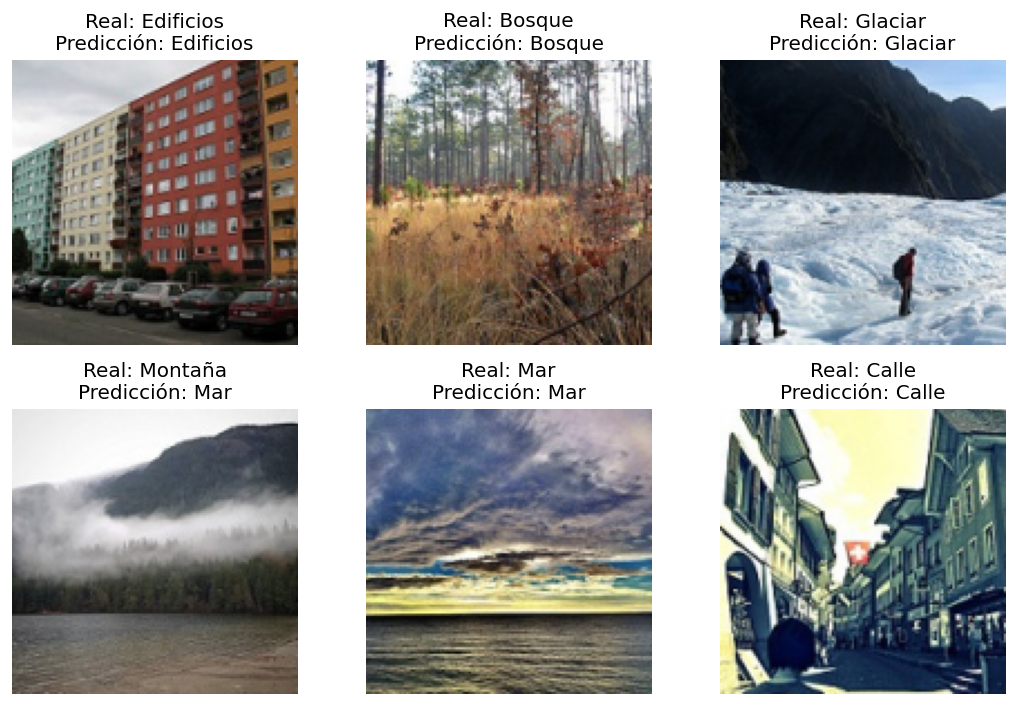

In [12]:
# Se guardó el modelo completo y se comprobó su recarga.
modelo_final.save(BASE / "modelos/modelo_final.keras")
config = {"autor": "Iris Giselle Balderas Arreola", "matricula": "A01752895", "lado": LADO,
          "clases": CLASES, "nombres": NOMBRES, "modelo_elegido": elegido}
(BASE / "modelos/clases.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
recargado = keras.models.load_model(BASE / "modelos/modelo_final.keras")
np.testing.assert_allclose(modelo_final(x_test[:6], training=False).numpy(), recargado(x_test[:6], training=False).numpy(), atol=1e-6)
fig, ejes = plt.subplots(2, 3, figsize=(9, 6))
for i, ax in enumerate(ejes.ravel()):
    fila = prueba[prueba.clase.eq(CLASES[i])].iloc[0]
    destino = BASE / "ejemplos" / f"{CLASES[i]}.jpg"
    shutil.copyfile(raiz_datos / fila.archivo, destino)
    resultado = predecir_imagen(destino, recargado)
    ax.imshow(cargar_imagen(destino).astype("uint8"))
    ax.set_title(f"Real: {NOMBRES[i]}\nPredicción: {resultado['escena']}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(BASE / "resultados/predicciones_ejemplo.png", dpi=140)
plt.show()
# Se eligió una imagen sin etiqueta cuyo hash no apareciera en los datos etiquetados.
hashes_etiquetados = set(inventario.hash_rgb)
foto_nueva = None
for candidata in sorted((raiz_datos / "seg_pred").rglob("*.jpg")):
    with Image.open(candidata) as foto:
        rgb = ImageOps.exif_transpose(foto).convert("RGB")
        huella = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
    if huella not in hashes_etiquetados:
        foto_nueva = candidata
        break
assert foto_nueva is not None
print("Se verificó que el ejemplo sin etiqueta no fuera una copia exacta de las imágenes etiquetadas.")
shutil.copyfile(foto_nueva, BASE / "ejemplos/sin_etiqueta.jpg")
print("Imagen sin etiqueta (no utilizada en los conjuntos etiquetados):", foto_nueva.name)
print(predecir_imagen(BASE / "ejemplos/sin_etiqueta.jpg", recargado))
print("Se verificó que las predicciones coincidieran al recargar el modelo.")
print("Tamaño del modelo (MB):", round((BASE / "modelos/modelo_final.keras").stat().st_size/1e6, 2))
print('Ejemplo en terminal: python predecir.py ejemplos/forest.jpg')